# Yang et al. 2016 — Fig. 2 and Supplementary Fig. 1 (e–h), reproduced with our model

This notebook re-runs Yang, Murray & Wang (2016) **Fig. 2b, c, e–g** and **Supplementary Fig. 1f–h**
using **this project's Model A**. Nothing is re-implemented here:

| what | taken from |
|---|---|
| dendrite, soma equations | `model/equations.py` (`eqs_dend`, `eqs_soma`) |
| excitatory synapse (NMDA saturation, Mg²⁺ block, AMPA) | `model/equations.py` (`eqs_synapse_plasticity`, plasticity frozen) |
| all biophysical constants | `model/parameters.py` |
| optional Yang NMDA-plastic weight | `model/context_circuit.py` (`nmda_plastic`) |
| simulations + plotting | `plotting/yang_fig2_supp1.py` |

**How to use it**
1. Run all cells once (*Run → Run All Cells*). The Supplementary Fig. 1 cell takes about 30 s; the Fig. 2 cell takes 1–3 min.
2. Change any value in the **Parameters** cell and re-run the figure cells: the figures are recomputed from the model.
3. Or use the **interactive panel** at the bottom: move the sliders and press *Run Interact*.

Changing `model/parameters.py` itself also changes these figures, because the values are read from it on every run
(re-run the setup cell after editing that file).

In [1]:
%matplotlib inline
import os, sys, importlib
PROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path[:0] = [os.path.join(PROOT, 'plotting'), os.path.join(PROOT, 'model'), PROOT]
import parameters, equations, context_circuit, yang_fig2_supp1 as Y
for m in (parameters, equations, context_circuit, Y):      # pick up edits to the model files
    importlib.reload(m)
from brian2 import nS, ms, pF, mV
print('model parameters loaded from', parameters.__file__)
print('e.g. gNMDA =', parameters.params['gNMDA'], '| gLDend_pyr =', parameters.params['gLDend_pyr'],
      '| gGABA =', parameters.params['gGABA'], '| tauGABA =', parameters.params['tauGABA'])

model parameters loaded from /run/media/raghav/New Volume/minsu/Thalamocortical_Gating_Project/model/parameters.py
e.g. gNMDA = 2.5 nS | gLDend_pyr = 4. nS | gGABA = 4. nS | tauGABA = 20. ms


## Parameters

`P` starts from `Y.DEFAULTS` (Yang's protocol values). Edit any line and re-run the figure cells.

* **`model_overrides`** changes the model itself: any key of `model/parameters.py` (e.g. `gNMDA`, `gLDend_pyr`,
  `gGABA`, `tauGABA`, `cDend_pyr`, `vHalfNMDA`). Units are required (`nS`, `ms`, `mV`, `pF`).
* The other entries are protocol settings from Yang's Methods (synapse counts, input and inhibition rates, coupling, durations).

Two deliberate deviations from Yang, both adjustable here:
* `couple_dend_nS = 0.8` for the single-dendrite panels. Yang's soma was free; here it is clamped at rest, and with Yang's
  in-vitro 4 nS coupling the clamped soma loads the branch so much that no NMDA plateau can form.
* `bg_exc_hz = 300` for the whole-neuron panels. Yang's 500 Hz background drives our soma to ~20 Hz; 300 Hz gives
  his ~3–4 Hz baseline.

In [2]:
P = dict(Y.DEFAULTS)

# ---- model parameters (model/parameters.py), override here --------------------------------
P['model_overrides'] = {
    # 'gNMDA': 2.5 * nS,        # NMDA conductance per synapse
    # 'gLDend_pyr': 4.0 * nS,   # dendritic leak
    # 'gGABA': 4.0 * nS,        # conductance per inhibitory event
    # 'tauGABA': 20.0 * ms,     # dendritic GABA decay
}
P['nmda_plastic'] = False       # True: Yang's synapse (learned weight scales NMDA); weights are frozen at w = 1 here
P['rho'] = 1 / 3                # synaptic state; w = 3*rho, so 1/3 -> w = 1 (Yang's pre-learning weight)

# ---- single dendrite: Supp. Fig. 1f-h, Fig. 2b,c ------------------------------------------
P['n_exc'] = 15                 # excitatory synapses per dendrite (Yang: 15)
P['volley_n'] = [5, 10, 15, 20, 25, 30, 35, 40]   # synapses activated together (panel f / 2b)
P['rates'] = [0, 5, 10, 20, 30, 40, 60, 80, 100]  # Poisson rate per synapse, Hz (panels g, h, 2c)
P['inh_off_hz'], P['inh_on_hz'] = 0.0, 30.0       # Supp. 1g,h inhibition levels (total rate onto the dendrite)
P['g_ampa_supp_nS'] = 2.5       # AMPA conductance for Supp. 1h
P['couple_dend_nS'] = 0.8       # dendrite-soma coupling for the single-dendrite panels
P['T_rate'] = 2.0               # s per rate point

# ---- whole neuron: Fig. 2c,e-g --------------------------------------------------------------
P['inh_closed_hz'], P['inh_open_hz'] = 35.0, 5.0  # inhibited vs disinhibited dendrite (disinhibition level 30 Hz)
P['n_dend_per_path'] = 2        # dendrites per pathway (Yang: 2)
P['u_max_hz'] = 40.0            # tuning curve u_E = u_max * exp(-z^2)
P['couple_vivo_nS'] = 0.8       # in-vivo dendrite-soma coupling
P['bg_exc_hz'], P['bg_inh_hz'] = 300.0, 150.0     # somatic background (2.5 nS AMPA, 4 nS GABA events)
P['n_z'], P['n_z2d'] = 13, 9    # stimulus points: 1-D tuning curve, 2-D grid per axis
P['T_neuron'] = 3.0             # s per neuron simulation
P['seed'] = 1
P

{'seed': 1,
 'rho': 0.3333333333333333,
 'nmda_plastic': False,
 'model_overrides': {},
 'volley_n': [5, 10, 15, 20, 25, 30, 35, 40],
 'T_trace': 0.4,
 'rates': [0, 5, 10, 20, 30, 40, 60, 80, 100],
 'T_rate': 2.0,
 'n_exc': 15,
 'n_inh': 1,
 'inh_off_hz': 0.0,
 'inh_on_hz': 30.0,
 'g_ampa_supp_nS': 2.5,
 'couple_dend_nS': 0.8,
 'inh_closed_hz': 35.0,
 'inh_open_hz': 5.0,
 'n_dend_per_path': 2,
 'u_max_hz': 40.0,
 'couple_vivo_nS': 0.8,
 'bg_exc_hz': 300.0,
 'bg_inh_hz': 150.0,
 'n_z': 13,
 'n_z2d': 9,
 'T_neuron': 3.0}

## Supplementary Fig. 1f–h — dendritic nonlinearity and its gating by inhibition

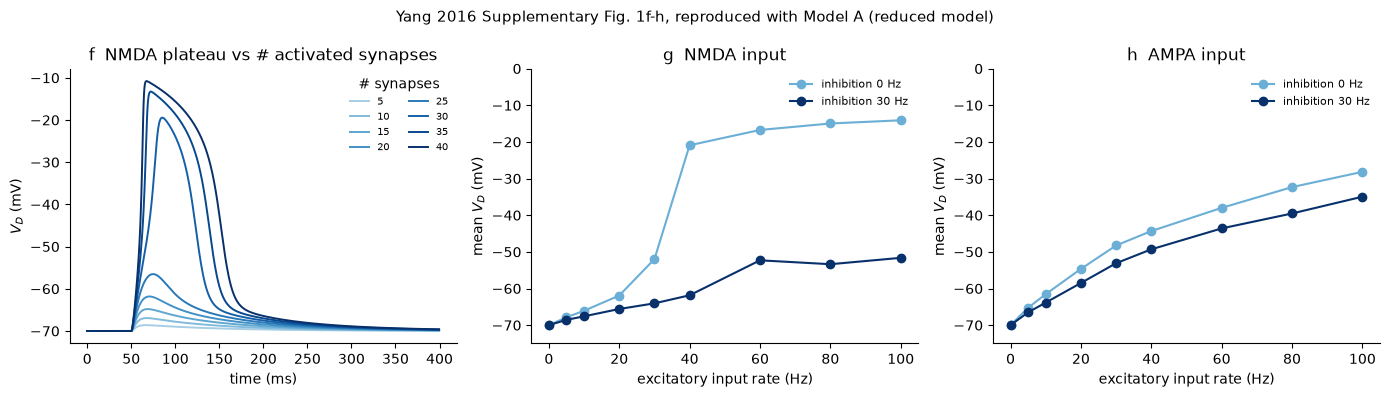

In [3]:
fig_s1, data_s1 = Y.plot_supp1(P)
fig_s1.savefig(os.path.join(PROOT, 'figures', 'yang_supp1_fgh_model.png'), dpi=150, facecolor='white')

## Fig. 2b, c, e–g — pathway-specific gating in a reduced compartmental neuron

gating selectivity S = (r_on - r_off)/(r_on + r_off) = 0.60


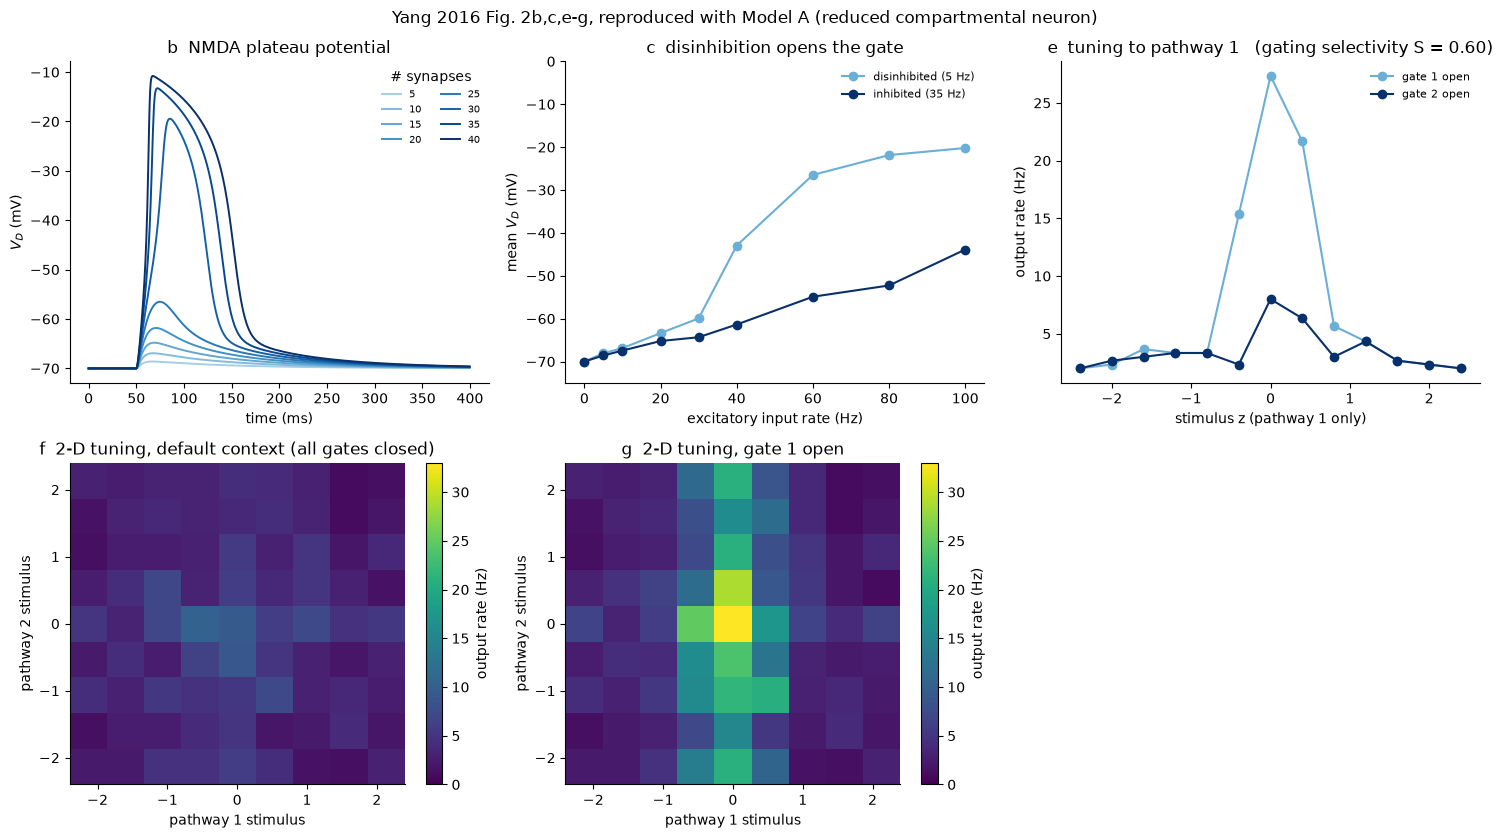

In [4]:
fig_2, data_2 = Y.plot_fig2(P)
fig_2.savefig(os.path.join(PROOT, 'figures', 'yang_fig2_model.png'), dpi=150, facecolor='white')
print(f"gating selectivity S = (r_on - r_off)/(r_on + r_off) = {data_2['S']:.2f}")

## Interactive panel

Move the sliders, choose a figure, and press **Run Interact**. Each run re-simulates the model with the new
values (Supp. Fig. 1 ≈ 30 s, Fig. 2 ≈ 1–3 min). Values not on a slider come from `P` above.

In [5]:
import ipywidgets as w

def run(figure, gNMDA_nS, gLDend_nS, gGABA_nS, tauGABA_ms, n_exc, couple_dend_nS, inh_on_hz,
        inh_closed_hz, inh_open_hz, u_max_hz, bg_exc_hz, nmda_plastic):
    Q = dict(P)
    Q['model_overrides'] = dict(P['model_overrides'], gNMDA=gNMDA_nS * nS, gLDend_pyr=gLDend_nS * nS,
                                gGABA=gGABA_nS * nS, tauGABA=tauGABA_ms * ms)
    Q.update(n_exc=n_exc, couple_dend_nS=couple_dend_nS, inh_on_hz=inh_on_hz, inh_closed_hz=inh_closed_hz,
             inh_open_hz=inh_open_hz, u_max_hz=u_max_hz, bg_exc_hz=bg_exc_hz, nmda_plastic=nmda_plastic)
    if figure == 'Supp. Fig. 1f-h':
        Y.plot_supp1(Q)
    else:
        f, d = Y.plot_fig2(Q)
        print(f"gating selectivity S = {d['S']:.2f}")

pp = parameters.params
sl = dict(continuous_update=False, style={'description_width': '140px'}, layout=w.Layout(width='420px'))
w.interact_manual(
    run,
    figure=w.Dropdown(options=['Supp. Fig. 1f-h', 'Fig. 2b,c,e-g'], description='figure'),
    gNMDA_nS=w.FloatSlider(value=float(pp['gNMDA'] / nS), min=0.5, max=6, step=0.25, description='gNMDA (nS)', **sl),
    gLDend_nS=w.FloatSlider(value=float(pp['gLDend_pyr'] / nS), min=1, max=10, step=0.5, description='dend leak (nS)', **sl),
    gGABA_nS=w.FloatSlider(value=float(pp['gGABA'] / nS), min=0, max=12, step=0.5, description='gGABA/event (nS)', **sl),
    tauGABA_ms=w.FloatSlider(value=float(pp['tauGABA'] / ms), min=5, max=50, step=1, description='tauGABA (ms)', **sl),
    n_exc=w.IntSlider(value=P['n_exc'], min=5, max=40, step=1, description='exc. synapses', **sl),
    couple_dend_nS=w.FloatSlider(value=P['couple_dend_nS'], min=0, max=4, step=0.1, description='coupling (nS)', **sl),
    inh_on_hz=w.FloatSlider(value=P['inh_on_hz'], min=0, max=80, step=5, description='Supp1 inhibition (Hz)', **sl),
    inh_closed_hz=w.FloatSlider(value=P['inh_closed_hz'], min=0, max=80, step=5, description='gate closed (Hz)', **sl),
    inh_open_hz=w.FloatSlider(value=P['inh_open_hz'], min=0, max=40, step=1, description='gate open (Hz)', **sl),
    u_max_hz=w.FloatSlider(value=P['u_max_hz'], min=10, max=100, step=5, description='peak input (Hz)', **sl),
    bg_exc_hz=w.FloatSlider(value=P['bg_exc_hz'], min=0, max=600, step=25, description='soma bg exc (Hz)', **sl),
    nmda_plastic=w.Checkbox(value=P['nmda_plastic'], description='Yang NMDA-plastic synapse'),
);

interactive(children=(Dropdown(description='figure', options=('Supp. Fig. 1f-h', 'Fig. 2b,c,e-g'), value='Supp…